# Notebook 4: Eksperimen Arsitektur Temporal — CRNN (CNN + BiGRU)

Di eksperimen sebelumnya (NB 02 dan 03), model CNN murni menggunakan GlobalAveragePooling2D yang merata-ratakan seluruh sumbu waktu. Akibatnya, informasi urutan melodi hilang — padahal setiap maqam punya alur nada yang khas dari pembukaan hingga penutupan.

Untuk mengatasi itu, di eksperimen ini lapisan pooling diganti dengan Bidirectional GRU (BiGRU) agar model bisa membaca pola temporal melodi secara berurutan. Input tetap menggunakan fitur MFCC agar bisa dibandingkan langsung dengan hasil NB 02.

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, regularizers
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

# 1. Kunci Random Seed agar eksperimen 100% Reproducible
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 2. Cari otomatis file maqam_2d_dataset.npz di /kaggle/input (Output dari Notebook 1)
DATASET_PATH = None
for root, _, files in os.walk("/kaggle/input"):
    if "maqam_2d_dataset.npz" in files:
        DATASET_PATH = os.path.join(root, "maqam_2d_dataset.npz")
        break

if DATASET_PATH is None:
    raise FileNotFoundError("File maqam_2d_dataset.npz tidak ditemukan! Pastikan Notebook 1 sudah ditambahkan via '+ Add Input'.")

print(f"[INFO] Memuat dataset fitur dari: {DATASET_PATH}")
data = np.load(DATASET_PATH, allow_pickle=True)

# Muat fitur MFCC (Height=130, Width=13, Channel=1)
# Menggunakan MFCC memungkinkan komparasi langsung head-to-head dengan Baseline 2D CNN (NB2)
X_train = data['X_train_mfcc'][..., np.newaxis]
y_train = data['y_train']

X_val   = data['X_val_mfcc'][..., np.newaxis]
y_val   = data['y_val']

X_test  = data['X_test_mfcc'][..., np.newaxis]
y_test  = data['y_test']

CLASS_NAMES = [str(c) for c in data['class_names']]
NUM_CLASSES = len(CLASS_NAMES)

print(f"[INFO] Kelas Maqam ({NUM_CLASSES}) : {CLASS_NAMES}")
print(f"[INFO] X_train shape    : {X_train.shape} | y_train shape: {y_train.shape}")
print(f"[INFO] X_val shape      : {X_val.shape}   | y_val shape  : {y_val.shape}")
print(f"[INFO] X_test shape     : {X_test.shape}  | y_test shape : {y_test.shape}")


[INFO] Memuat dataset fitur dari: /kaggle/input/01-preprocessing-extraction/maqam_2d_dataset.npz
[INFO] Kelas Maqam (8) : ['Ajam', 'Bayati', 'Hijaz', 'Kurdi', 'Nahawand', 'Rast', 'Saba', 'Sikah']
[INFO] X_train shape    : (6158, 130, 13, 1) | y_train shape: (6158,)
[INFO] X_val shape      : (385, 130, 13, 1)   | y_val shape  : (385,)
[INFO] X_test shape     : (385, 130, 13, 1)  | y_test shape : (385,)


### 2. Membangun Arsitektur Hibrida CRNN (CNN + BiGRU)



In [2]:
def build_crnn_hybrid(input_shape, num_classes=8, l2_reg=1e-4, name="CRNN_Hybrid_BiGRU"):
    l2 = regularizers.l2(l2_reg)
    inputs = layers.Input(shape=input_shape, name="input_acoustic")
    
    # -------------------------------------------------------------
    # BAGIAN 1: CNN Feature Extractor (Representasi Spasial-Akustik)
    # -------------------------------------------------------------
    # Blok Konvolusi 1
    x = layers.Conv2D(32, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv1")(inputs)
    x = layers.BatchNormalization(name="bn1")(x)
    x = layers.Activation('relu', name="relu1")(x)
    x = layers.MaxPooling2D((2, 2), name="pool1")(x)  # (130, 13) -> (65, 6)
    x = layers.SpatialDropout2D(0.20, name="spatial_drop1")(x)
    
    # Blok Konvolusi 2 (Pooling pada sumbu waktu saja agar resolusi frekuensi terjaga)
    x = layers.Conv2D(64, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv2")(x)
    x = layers.BatchNormalization(name="bn2")(x)
    x = layers.Activation('relu', name="relu2")(x)
    x = layers.MaxPooling2D((2, 1), name="pool2")(x)  # (65, 6) -> (32, 6)
    x = layers.SpatialDropout2D(0.20, name="spatial_drop2")(x)
    
    # Blok Konvolusi 3
    x = layers.Conv2D(128, (3, 3), padding='same', use_bias=False, kernel_regularizer=l2, name="conv3")(x)
    x = layers.BatchNormalization(name="bn3")(x)
    x = layers.Activation('relu', name="relu3")(x)
    x = layers.MaxPooling2D((2, 1), name="pool3")(x)  # (32, 6) -> (16, 6)
    x = layers.SpatialDropout2D(0.25, name="spatial_drop3")(x)
    
    # -------------------------------------------------------------
    # BAGIAN 2: Jembatan Reshape (Menjaga Dimensi Temporal Waktu)
    # -------------------------------------------------------------
    # Bentuk tensor saat ini: (Batch, Time=16, Freq=6, Channels=128)
    time_steps = x.shape[1]
    feature_dim = x.shape[2] * x.shape[3]  # 6 * 128 = 768
    
    x = layers.Reshape(target_shape=(time_steps, feature_dim), name="temporal_reshape")(x)
    
    # Proyeksi linear awal untuk menyederhanakan representasi sebelum masuk RNN
    x = layers.Dense(128, kernel_regularizer=l2, name="dense_proj")(x)
    x = layers.BatchNormalization(name="bn_proj")(x)
    x = layers.Activation('relu', name="relu_proj")(x)
    x = layers.Dropout(0.25, name="drop_proj")(x)
    
    # -------------------------------------------------------------
    # BAGIAN 3: Recurrent Modeling (Bidirectional GRU)
    # -------------------------------------------------------------
    # Lapisan BiGRU 1 (Return Sequences=True untuk estafet sekuens waktu)
    x = layers.Bidirectional(
        layers.GRU(64, return_sequences=True, dropout=0.25, kernel_regularizer=l2),
        name="bigru_layer1"
    )(x)
    
    # Lapisan BiGRU 2 (Return Sequences=False untuk merangkum representasi temporal utuh)
    x = layers.Bidirectional(
        layers.GRU(64, return_sequences=False, dropout=0.25, kernel_regularizer=l2),
        name="bigru_layer2"
    )(x)
    
    # -------------------------------------------------------------
    # BAGIAN 4: Classifier Head
    # -------------------------------------------------------------
    x = layers.Dense(128, use_bias=False, kernel_regularizer=l2, name="dense_clf")(x)
    x = layers.BatchNormalization(name="bn_clf")(x)
    x = layers.Activation('relu', name="relu_clf")(x)
    x = layers.Dropout(0.40, name="dropout_clf")(x)
    outputs = layers.Dense(num_classes, activation='softmax', name="output_maqam")(x)
    
    model = models.Model(inputs=inputs, outputs=outputs, name=name)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_crnn_hybrid(input_shape=X_train.shape[1:], num_classes=NUM_CLASSES)
model.summary()


Model: "CRNN_Hybrid_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_acoustic (InputLayer)     │ (None, 130, 13, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 130, 13, 32)    │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 130, 13, 32)    │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 130, 13, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 65, 6, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop1                   │ (None, 65, 6, 32)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 65, 6, 64)      │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 65, 6, 64)      │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 65, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 32, 6, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop2                   │ (None, 32, 6, 64)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 32, 6, 128)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 32, 6, 128)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 32, 6, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 16, 6, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_drop3                   │ (None, 16, 6, 128)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_reshape (Reshape)      │ (None, 16, 768)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_proj (Dense)              │ (None, 16, 128)        │        98,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_proj (BatchNormalization)    │ (None, 16, 128)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_proj (Activation)          │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_proj (Dropout)             │ (None, 16, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bigru_layer1 (Bidirectional)    │ (None, 16, 128)        │        74,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bigru_layer2 (Bidirectional)    │ (None, 128)            │        74,496 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 359,208 (1.37 MB)

 Trainable params: 358,248 (1.37 MB)

 Non-trainable params: 960 (3.75 KB)

### 3. Pelatihan Model CRNN dengan Callbacks Adaptif


In [3]:
BEST_MODEL_PATH = "/kaggle/working/model_exp3_crnn.keras"

cb_list = [
    callbacks.ModelCheckpoint(
        filepath=BEST_MODEL_PATH,
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-6,
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    )
]

EPOCHS = 80
BATCH_SIZE = 32

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=cb_list,
    verbose=1
)


Epoch 1/80


E0000 00:00:1794888182.221478      24 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/CRNN_Hybrid_BiGRU_1/spatial_drop1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1761 - loss: 2.4931
Epoch 1: val_loss improved from None to 1.96572, saving model to /kaggle/working/model_exp3_crnn.keras

Epoch 1: finished saving model to /kaggle/working/model_exp3_crnn.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.2072 - loss: 2.3363 - val_accuracy: 0.2805 - val_loss: 1.9657 - learning_rate: 0.0010
Epoch 2/80
193/193 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.2734 - loss: 2.0711
Epoch 2: val_loss improved from 1.96572 to 1.78065, saving model to /kaggle/working/model_exp3_crnn.keras

Epoch 2: finished saving model to /kaggle/working/model_exp3_crnn.keras
193/193 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 0.2868 - loss: 2.0322 - val_accuracy: 0.3740 - val_loss: 1.7807 - learning_rate: 0.0010
Epoch 3/80
192/193 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.3223 - loss: 1.9279
Epoch 3: val_loss improved from 1.78065 to 1.71155, saving model to /kaggle/working/model_exp3_crnn.keras

Epo

### 4. Visualisasi Kurva Loss & Accuracy (CRNN Hibrida)


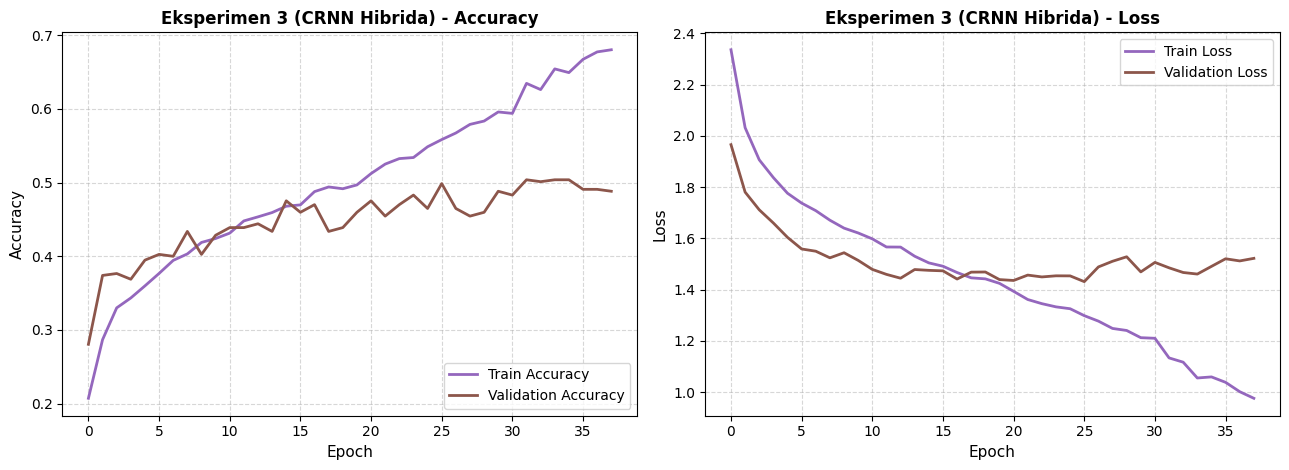

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Plot Accuracy
axes[0].plot(history.history['accuracy'], label='Train Accuracy', color='#9467bd', linewidth=2)
axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy', color='#8c564b', linewidth=2)
axes[0].set_title('Eksperimen 3 (CRNN Hibrida) - Accuracy', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=11)
axes[0].set_ylabel('Accuracy', fontsize=11)
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Plot Loss
axes[1].plot(history.history['loss'], label='Train Loss', color='#9467bd', linewidth=2)
axes[1].plot(history.history['val_loss'], label='Validation Loss', color='#8c564b', linewidth=2)
axes[1].set_title('Eksperimen 3 (CRNN Hibrida) - Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=11)
axes[1].set_ylabel('Loss', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/kurva_training_exp3_crnn.png", dpi=300)
plt.show()


### 5. Evaluasi Komprehensif pada Test Set (CRNN Hibrida)


HASIL EVALUASI EKSPERIMEN 3: CRNN HIBRIDA (CNN + BiGRU) (TEST SET)
Test Accuracy         : 46.75%
Macro Precision       : 45.16%
Macro Recall          : 43.82%
Macro F1-Score        : 44.17%
Weighted F1-Score     : 46.41%

Classification Report per Kelas Maqam:

              precision    recall  f1-score   support

        Ajam     0.3600    0.3462    0.3529        52
      Bayati     0.3030    0.2857    0.2941        35
       Hijaz     0.4381    0.5750    0.4973        80
       Kurdi     0.2500    0.1765    0.2069        34
    Nahawand     0.4545    0.4286    0.4412        35
        Rast     0.5714    0.4444    0.5000        54
        Saba     0.8400    0.8077    0.8235        52
       Sikah     0.3958    0.4419    0.4176        43

    accuracy                         0.4675       385
   macro avg     0.4516    0.4382    0.4417       385
weighted avg     0.4684    0.4675    0.4641       385



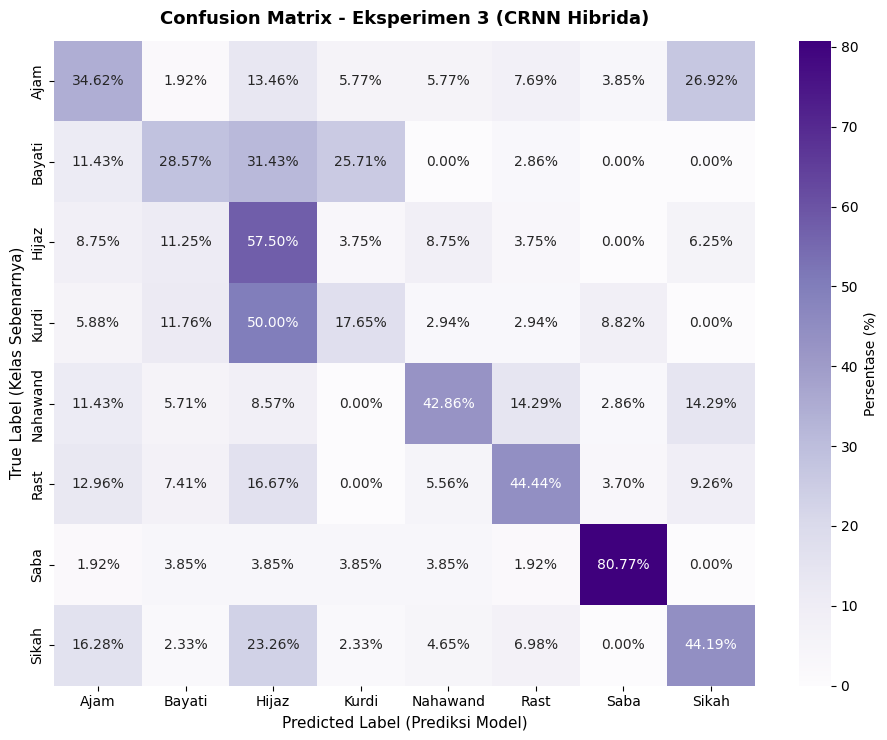

[SUKSES] Hasil evaluasi & model terbaik Eksperimen 3 berhasil disimpan.


In [5]:
# Muat bobot model terbaik
best_model = tf.keras.models.load_model(BEST_MODEL_PATH)

# Prediksi label pada Test Set
y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Hitung metrik evaluasi
test_acc = accuracy_score(y_test, y_pred)
prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
prec_weighted, rec_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)

print("=" * 70)
print("HASIL EVALUASI EKSPERIMEN 3: CRNN HIBRIDA (CNN + BiGRU) (TEST SET)")
print("=" * 70)
print(f"Test Accuracy         : {test_acc * 100:.2f}%")
print(f"Macro Precision       : {prec_macro * 100:.2f}%")
print(f"Macro Recall          : {rec_macro * 100:.2f}%")
print(f"Macro F1-Score        : {f1_macro * 100:.2f}%")
print(f"Weighted F1-Score     : {f1_weighted * 100:.2f}%")
print("=" * 70)
print("\nClassification Report per Kelas Maqam:\n")
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))

# Confusion Matrix Persentase
cm = confusion_matrix(y_test, y_pred)
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(9.5, 7.5))
sns.heatmap(
    cm_percent, annot=True, fmt='.2f', cmap='Purples',
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={'label': 'Persentase (%)'}
)
for t in plt.gca().texts:
    t.set_text(t.get_text() + "%")

plt.title("Confusion Matrix - Eksperimen 3 (CRNN Hibrida)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Predicted Label (Prediksi Model)", fontsize=11)
plt.ylabel("True Label (Kelas Sebenarnya)", fontsize=11)
plt.tight_layout()
plt.savefig("/kaggle/working/cm_exp3_crnn.png", dpi=300)
plt.show()

# Simpan hasil evaluasi ke file .npz
np.savez(
    "/kaggle/working/eval_exp3_crnn.npz",
    experiment_name="Exp 3: CRNN Hybrid (BiGRU)",
    test_acc=float(test_acc),
    prec_macro=float(prec_macro),
    rec_macro=float(rec_macro),
    f1_macro=float(f1_macro),
    prec_weighted=float(prec_weighted),
    rec_weighted=float(rec_weighted),
    f1_weighted=float(f1_weighted),
    y_test=y_test,
    y_pred=y_pred,
    class_names=np.array(CLASS_NAMES, dtype=object),
    history_acc=history.history['accuracy'],
    history_val_acc=history.history['val_accuracy'],
    history_loss=history.history['loss'],
    history_val_loss=history.history['val_loss']
)
print("[SUKSES] Hasil evaluasi & model terbaik Eksperimen 3 berhasil disimpan.")
